# Practical-1: Data Preprocessing & Feature Engineering
### Customer Churn Prediction: E-commerce Dataset


---
# Setup: libraries and folder paths

In [3]:
import warnings
warnings.filterwarnings("ignore")

import os, json, sqlite3, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

# Folder paths (notebook lives in Notebooks/, data in Data/)
ROOT = os.path.abspath("..")
RAW, EXT, PROC = (os.path.join(ROOT, "Data", d) for d in ("Raw", "External", "Processed"))
REPORTS, VIZ = os.path.join(ROOT, "Reports"), os.path.join(ROOT, "Visualization")
for p in (RAW, EXT, PROC, REPORTS, VIZ):
    os.makedirs(p, exist_ok=True)

def save_fig(name):
    """Save the current chart into Visualization/ and show it."""
    plt.tight_layout()
    plt.savefig(os.path.join(VIZ, name), dpi=150, bbox_inches="tight")
    plt.show()

print("pandas", pd.__version__, "| numpy", np.__version__)
print("Project root:", ROOT)

pandas 2.3.3 | numpy 2.3.5
Project root: /home/claude/dp-feature-engineering


---
# Part B: Data Acquisition (Q5)

The company data arrives from **four different sources**. Our Kaggle download is one CSV, so we first **split it into three files** (CSV, JSON, SQLite database) to simulate this situation, then load each one with the matching tool.

### Step 1: Load the original dataset and split it into 3 formats

In [4]:
source = pd.read_csv(os.path.join(RAW, "ecommerce_churn.csv"))
print("Original dataset shape:", source.shape)

n = len(source)
part1, part2, part3 = source.iloc[: n // 3], source.iloc[n // 3 : 2 * n // 3], source.iloc[2 * n // 3 :]

csv_path  = os.path.join(RAW, "Customers_Part1.csv")
json_path = os.path.join(RAW, "Customers_Part2.json")
db_path   = os.path.join(RAW, "Customers_Part3.db")

part1.to_csv(csv_path, index=False)
part2.to_json(json_path, orient="records", indent=2)

conn = sqlite3.connect(db_path)
part3.to_sql("customers", conn, if_exists="replace", index=False)
conn.close()

print(f"Rows per part -> CSV: {len(part1)}, JSON: {len(part2)}, SQL: {len(part3)}")

Original dataset shape: (5630, 20)
Rows per part -> CSV: 1876, JSON: 1877, SQL: 1877


### Step 2: Load the CSV file with Pandas

In [5]:
df_csv = pd.read_csv(csv_path)
print("CSV shape:", df_csv.shape)
df_csv.head()

CSV shape: (1876, 20)


,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,160
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,121
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,130


### Step 3: Parse the JSON file
"Parsing" means converting JSON text into Python objects. We parse it with the `json` module first, then flatten it into a table with `json_normalize`.

In [6]:
with open(json_path) as f:
    records = json.load(f)                  # JSON text -> Python list of dictionaries

print("Type:", type(records).__name__, "| records:", len(records))
print("First record:", records[0])

df_json = pd.json_normalize(records)        # flatten into a DataFrame
print("\nJSON shape:", df_json.shape)
df_json.head()

Type: list | records: 1877
First record: {'CustomerID': 51877, 'Churn': 0, 'Tenure': 5.0, 'PreferredLoginDevice': 'Mobile Phone', 'CityTier': 1, 'WarehouseToHome': 9.0, 'PreferredPaymentMode': 'Debit Card', 'Gender': 'Female', 'HourSpendOnApp': 2.0, 'NumberOfDeviceRegistered': 3, 'PreferedOrderCat': 'Fashion', 'SatisfactionScore': 1, 'MaritalStatus': 'Single', 'NumberOfAddress': 4, 'Complain': 0, 'OrderAmountHikeFromlastYear': 15.0, 'CouponUsed': 6.0, 'OrderCount': 7.0, 'DaySinceLastOrder': None, 'CashbackAmount': 212}

JSON shape: (1877, 20)


,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,51877,0,5.0,Mobile Phone,1,9.0,Debit Card,Female,2.0,3,Fashion,1,Single,4,0,15.0,6.0,7.0,NaN,212
1,51878,0,20.0,Mobile Phone,3,20.0,E wallet,Male,2.0,3,Laptop & Accessory,5,Single,3,0,12.0,1.0,1.0,7.0,150
2,51879,0,13.0,Computer,3,11.0,Debit Card,Male,2.0,4,Fashion,5,Married,6,1,21.0,0.0,1.0,12.0,205
3,51880,0,26.0,Mobile Phone,1,13.0,Debit Card,Male,2.0,1,Grocery,3,Married,4,0,19.0,0.0,NaN,3.0,248
4,51881,0,14.0,Mobile Phone,2,16.0,UPI,Male,3.0,4,Others,1,Married,4,0,15.0,NaN,12.0,6.0,291


### Step 4: Connect to the SQL database and fetch records

In [7]:
conn = sqlite3.connect(db_path)

# Which tables exist?
tables = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table';", conn)
print("Tables in database:", tables["name"].tolist())

# Fetch all records
df_sql = pd.read_sql_query("SELECT * FROM customers", conn)
print("SQL shape:", df_sql.shape)

# Example of a filtered query: churned customers with a complaint
sample = pd.read_sql_query(
    "SELECT CustomerID, Tenure, Complain, Churn FROM customers WHERE Churn = 1 AND Complain = 1 LIMIT 5", conn)
conn.close()

display(sample)
df_sql.head()

Tables in database: ['customers']
SQL shape: (1877, 20)


,CustomerID,Tenure,Complain,Churn
0,53801,1.0,1,1
1,53827,1.0,1,1
2,53844,1.0,1,1
3,53858,1.0,1,1
4,53862,4.0,1,1


,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,53754,0,3.0,Mobile Phone,3,26.0,Debit Card,Male,4.0,5,Laptop & Accessory,3,Married,3,0,15.0,2.0,2.0,NaN,211
1,53755,0,4.0,Phone,2,7.0,Debit Card,Male,3.0,4,Mobile Phone,3,Married,2,0,22.0,1.0,2.0,4.0,146
2,53756,0,29.0,Mobile Phone,1,11.0,Debit Card,Male,2.0,4,Laptop & Accessory,3,Divorced,2,1,17.0,1.0,2.0,3.0,165
3,53757,0,7.0,Mobile Phone,1,11.0,Credit Card,Female,3.0,5,Mobile Phone,4,Divorced,10,0,12.0,1.0,2.0,3.0,163
4,53758,0,21.0,Mobile Phone,3,21.0,Credit Card,Female,4.0,4,Laptop & Accessory,3,Divorced,5,1,18.0,2.0,2.0,3.0,171


### Step 5: Fetch data from a REST API
We call a public dummy REST API (`jsonplaceholder`). If there is no internet access, the code falls back to a small **offline sample** so the notebook still runs; the printed message tells you which one was used.

In [8]:
API_URL = "https://jsonplaceholder.typicode.com/users"

try:
    response = requests.get(API_URL, timeout=10)
    response.raise_for_status()
    print("API status code:", response.status_code)          # 200 = success
    df_api = pd.json_normalize(response.json())              # nested JSON -> flat columns
    api_file = "api_users.csv"
    print("Source: LIVE API")
except Exception as e:
    print("API not reachable:", type(e).__name__)
    df_api = pd.DataFrame({
        "id": range(1, 11),
        "name": [f"Sample User {i}" for i in range(1, 11)],
        "email": [f"user{i}@example.com" for i in range(1, 11)],
        "address.city": ["City A", "City B"] * 5,
    })
    api_file = "api_users_offline_sample.csv"
    print("Source: OFFLINE SAMPLE (re-run with internet to fetch the live API)")

df_api.to_csv(os.path.join(EXT, api_file), index=False)
print("API data shape:", df_api.shape)
df_api[[c for c in ["id", "name", "email", "address.city"] if c in df_api.columns]].head()

API not reachable: ConnectionError
Source: OFFLINE SAMPLE (re-run with internet to fetch the live API)
API data shape: (10, 4)


,id,name,email,address.city
0,1,Sample User 1,user1@example.com,City A
1,2,Sample User 2,user2@example.com,City B
2,3,Sample User 3,user3@example.com,City A
3,4,Sample User 4,user4@example.com,City B
4,5,Sample User 5,user5@example.com,City A


### Step 6: Merge CSV + JSON + SQL into one dataset

In [9]:
df = pd.concat([df_csv, df_json, df_sql], ignore_index=True)

print("Merged shape:", df.shape)
print("Matches original shape:", df.shape == source.shape)
print("Same CustomerIDs as original:", set(df["CustomerID"]) == set(source["CustomerID"]))
df.head()

Merged shape: (5630, 20)
Matches original shape: True
Same CustomerIDs as original: True


,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,160
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,121
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,130


**Interpretation:** Data was loaded from three formats with the matching tools: `read_csv` for CSV, `json.load` + `json_normalize` for JSON, and `sqlite3` + `read_sql_query` for the SQL database. The three parts were combined with `pd.concat` into one DataFrame of **5,630 rows x 20 columns**, which matches the original, so nothing was lost. The API data contains dummy users and has no customer key, so it is only a fetch demonstration and is stored separately in `Data/External/`.

---
# Part C: Data Understanding & Cleaning

## Q6. Initial exploration

In [10]:
df_raw = df.copy()          # untouched copy, used later for the "before cleaning" profiling report
df.head()

,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,160
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,121
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,130


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CustomerID                   5630 non-null   int64  
 1   Churn                        5630 non-null   int64  
 2   Tenure                       5366 non-null   float64
 3   PreferredLoginDevice         5630 non-null   object 
 4   CityTier                     5630 non-null   int64  
 5   WarehouseToHome              5379 non-null   float64
 6   PreferredPaymentMode         5630 non-null   object 
 7   Gender                       5630 non-null   object 
 8   HourSpendOnApp               5375 non-null   float64
 9   NumberOfDeviceRegistered     5630 non-null   int64  
 10  PreferedOrderCat             5630 non-null   object 
 11  SatisfactionScore            5630 non-null   int64  
 12  MaritalStatus                5630 non-null   object 
 13  NumberOfAddress   

In [12]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
CustomerID,5630.0,52815.500000,1625.385339,50001.0,51408.25,52815.5,54222.75,55630.0
Churn,5630.0,0.168384,0.374240,0.0,0.00,0.0,0.00,1.0
Tenure,5366.0,10.189899,8.557241,0.0,2.00,9.0,16.00,61.0
CityTier,5630.0,1.654707,0.915389,1.0,1.00,1.0,3.00,3.0
WarehouseToHome,5379.0,15.639896,8.531475,5.0,9.00,14.0,20.00,127.0
HourSpendOnApp,5375.0,2.931535,0.721926,0.0,2.00,3.0,3.00,5.0
NumberOfDeviceRegistered,5630.0,3.688988,1.023999,1.0,3.00,4.0,4.00,6.0
SatisfactionScore,5630.0,3.066785,1.380194,1.0,2.00,3.0,4.00,5.0
NumberOfAddress,5630.0,4.214032,2.583586,1.0,2.00,3.0,6.00,22.0
Complain,5630.0,0.284902,0.451408,0.0,0.00,0.0,1.00,1.0


### Missing values and duplicates

In [13]:
def quality_report(data, dup_label="(duplicate rows)"):
    """Column-wise data quality summary (dtype, missing, unique) + duplicate row count."""
    rep = pd.DataFrame({
        "dtype": data.dtypes.astype(str),
        "missing_count": data.isnull().sum(),
        "missing_pct": (data.isnull().mean() * 100).round(2),
        "unique_values": data.nunique(),
    })
    dups = int(data.duplicated().sum())
    rep.loc[dup_label] = ["-", dups, round(dups / len(data) * 100, 2), "-"]
    return rep

dq_before = quality_report(df)
dq_before.to_csv(os.path.join(REPORTS, "data_quality_report.csv"))
print("Columns with missing values:")
display(dq_before[dq_before["missing_count"] > 0])
print("Total missing cells:", int(df.isnull().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

Columns with missing values:


,dtype,missing_count,missing_pct,unique_values
Tenure,float64,264,4.69,36
WarehouseToHome,float64,251,4.46,34
HourSpendOnApp,float64,255,4.53,6
OrderAmountHikeFromlastYear,float64,265,4.71,16
CouponUsed,float64,256,4.55,17
OrderCount,float64,258,4.58,16
DaySinceLastOrder,float64,307,5.45,22


Total missing cells: 1856
Duplicate rows: 0


In [14]:
# Inconsistent category labels
for col in ["PreferredLoginDevice", "PreferredPaymentMode", "PreferedOrderCat"]:
    print(f"\n{col}:")
    print(df[col].value_counts())


PreferredLoginDevice:
PreferredLoginDevice
Mobile Phone    2765
Computer        1634
Phone           1231
Name: count, dtype: int64

PreferredPaymentMode:
PreferredPaymentMode
Debit Card          2314
Credit Card         1501
E wallet             614
UPI                  414
COD                  365
CC                   273
Cash on Delivery     149
Name: count, dtype: int64

PreferedOrderCat:
PreferedOrderCat
Laptop & Accessory    2050
Mobile Phone          1271
Fashion                826
Mobile                 809
Grocery                410
Others                 264
Name: count, dtype: int64


**Interpretation:** Seven numeric columns have about 250-310 missing values each (roughly 4-5% per column). There are **no duplicate rows**. The categorical columns contain **inconsistent labels that mean the same thing** (`Phone` vs `Mobile Phone`, `CC` vs `Credit Card`, `COD` vs `Cash on Delivery`, `Mobile` vs `Mobile Phone`), which would wrongly be treated as separate categories by a model. Several count-like columns (e.g. `Tenure`, `OrderCount`) are stored as decimals because of the missing values.

## Q7. Data cleaning

In [15]:
# 1) Duplicates
before = len(df)
df = df.drop_duplicates()
print(f"Duplicates removed: {before - len(df)}")

# 2) Fix inconsistent labels
df["PreferredLoginDevice"] = df["PreferredLoginDevice"].replace({"Phone": "Mobile Phone"})
df["PreferredPaymentMode"] = df["PreferredPaymentMode"].replace({"CC": "Credit Card", "COD": "Cash on Delivery"})
df["PreferedOrderCat"]     = df["PreferedOrderCat"].replace({"Mobile": "Mobile Phone"})

for col in ["PreferredLoginDevice", "PreferredPaymentMode", "PreferedOrderCat"]:
    print(f"\n{col}: {df[col].nunique()} categories -> {sorted(df[col].unique())}")

Duplicates removed: 0

PreferredLoginDevice: 2 categories -> ['Computer', 'Mobile Phone']

PreferredPaymentMode: 5 categories -> ['Cash on Delivery', 'Credit Card', 'Debit Card', 'E wallet', 'UPI']

PreferedOrderCat: 5 categories -> ['Fashion', 'Grocery', 'Laptop & Accessory', 'Mobile Phone', 'Others']


In [16]:
# 3) Missing values: median imputation (robust to outliers; these columns are skewed counts)
missing_cols = [c for c in df.columns if df[c].isnull().any()]
print("Imputing with median:", missing_cols)
for c in missing_cols:
    df[c] = df[c].fillna(df[c].median())

# 4) Correct data types: these columns only contain whole numbers
int_cols = ["Tenure", "WarehouseToHome", "HourSpendOnApp", "OrderAmountHikeFromlastYear",
            "CouponUsed", "OrderCount", "DaySinceLastOrder"]
df[int_cols] = df[int_cols].astype(int)

# 5) Drop irrelevant column: CustomerID is only an identifier, it carries no predictive signal
df = df.drop(columns=["CustomerID"])

print("\nMissing values left:", int(df.isnull().sum().sum()))
df.dtypes

Imputing with median: ['Tenure', 'WarehouseToHome', 'HourSpendOnApp', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder']

Missing values left: 0


Churn                           int64
Tenure                          int64
PreferredLoginDevice           object
CityTier                        int64
WarehouseToHome                 int64
PreferredPaymentMode           object
Gender                         object
HourSpendOnApp                  int64
NumberOfDeviceRegistered        int64
PreferedOrderCat               object
SatisfactionScore               int64
MaritalStatus                  object
NumberOfAddress                 int64
Complain                        int64
OrderAmountHikeFromlastYear     int64
CouponUsed                      int64
OrderCount                      int64
DaySinceLastOrder               int64
CashbackAmount                  int64
dtype: object

### Outlier check (IQR method)

In [17]:
def iqr_bounds(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

check_cols = ["Tenure", "WarehouseToHome", "NumberOfAddress", "OrderCount", "CouponUsed",
              "CashbackAmount", "DaySinceLastOrder"]
rows = []
for c in check_cols:
    lo, hi = iqr_bounds(df[c])
    rows.append([c, int(((df[c] < lo) | (df[c] > hi)).sum()), round(lo, 1), round(hi, 1), df[c].max()])
outliers = pd.DataFrame(rows, columns=["column", "outliers", "lower_fence", "upper_fence", "max_value"])
outliers

,column,outliers,lower_fence,upper_fence,max_value
0,Tenure,4,-15.0,33.0,61
1,WarehouseToHome,2,-7.5,36.5,127
2,NumberOfAddress,4,-4.0,12.0,22
3,OrderCount,703,-2.0,6.0,16
4,CouponUsed,629,-0.5,3.5,16
5,CashbackAmount,447,71.0,271.0,325
6,DaySinceLastOrder,62,-5.5,14.5,46


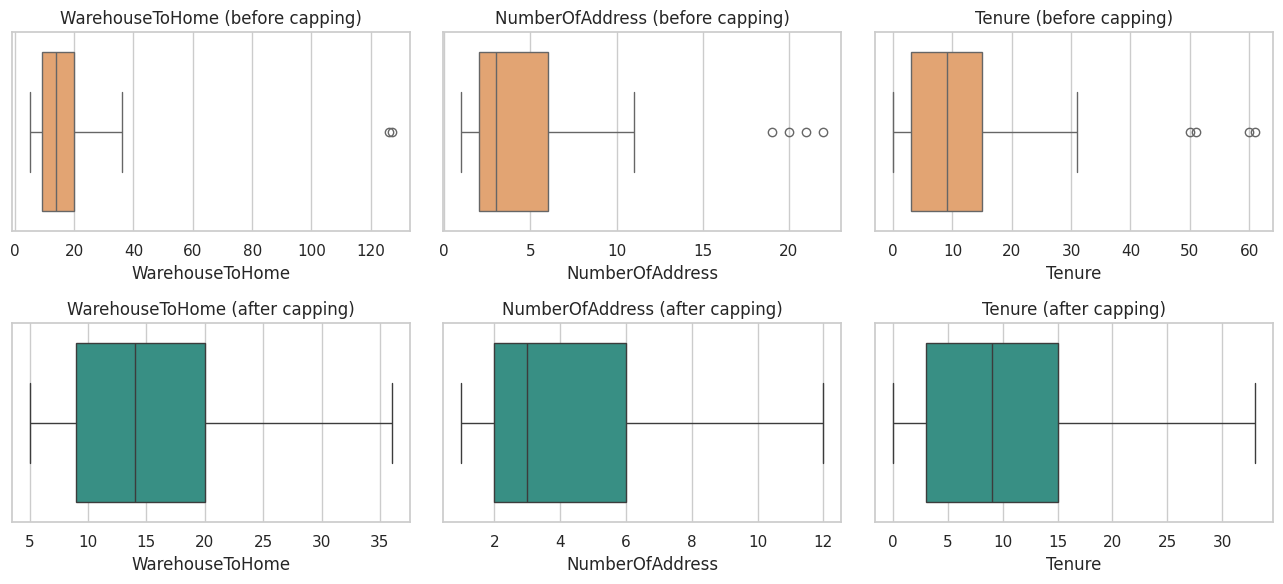

In [18]:
# Cap only the columns with a few extreme (likely erroneous) values.
# OrderCount, CouponUsed, CashbackAmount have many high values = genuine heavy buyers, so they are kept.
cap_cols = ["WarehouseToHome", "NumberOfAddress", "Tenure"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for i, c in enumerate(cap_cols):
    sns.boxplot(x=df[c], ax=axes[0, i], color="#f4a261")
    axes[0, i].set_title(f"{c} (before capping)")
    lo, hi = iqr_bounds(df[c])
    df[c] = df[c].clip(lower=lo, upper=hi).astype(int)
    sns.boxplot(x=df[c], ax=axes[1, i], color="#2a9d8f")
    axes[1, i].set_title(f"{c} (after capping)")
save_fig("01_outlier_capping.png")

In [19]:
dq_after = quality_report(df, dup_label="(rows identical on all features, different customers)")
dq_after.to_csv(os.path.join(REPORTS, "data_quality_report_after_cleaning.csv"))
print("Shape after cleaning:", df.shape)
print("Total missing cells:", int(df.isnull().sum().sum()))
print("Rows identical on all remaining features:", int(df.duplicated().sum()),
      "(NOT true duplicates: they were checked with CustomerID before it was dropped, and the rows come from different customers)")
dq_after

Shape after cleaning: (5630, 19)
Total missing cells: 0
Rows identical on all remaining features: 560 (NOT true duplicates: they were checked with CustomerID before it was dropped, and the rows come from different customers)


,dtype,missing_count,missing_pct,unique_values
Churn,int64,0,0.00,2
Tenure,int64,0,0.00,33
PreferredLoginDevice,object,0,0.00,2
CityTier,int64,0,0.00,3
WarehouseToHome,int64,0,0.00,32
PreferredPaymentMode,object,0,0.00,5
Gender,object,0,0.00,2
HourSpendOnApp,int64,0,0.00,6
NumberOfDeviceRegistered,int64,0,0.00,6
PreferedOrderCat,object,0,0.00,5


---
# Feature Engineering

1. **Add `Age` and `Income`** (simulated, see assumptions at the top).
2. Create new features: `AgeGroup`, `CashbackPerOrder`, `IsNewCustomer`.
3. Encode categorical variables (one-hot) and scale numeric variables to make an ML-ready file.

In [20]:
# 1) Synthetic Age and Income (independent of churn on purpose)
np.random.seed(42)
n = len(df)
df["Age"] = np.clip(np.random.normal(35, 10, n), 18, 65).round().astype(int)

tier_base_income = {1: 60000, 2: 45000, 3: 35000}          # richer cities -> higher base income
df["Income"] = (df["CityTier"].map(tier_base_income)
                + (df["Age"] - 18) * 400
                + np.random.normal(0, 8000, n)).clip(15000, 150000).round(-2)

# 2) New features
df["AgeGroup"] = pd.cut(df["Age"], bins=[17, 25, 35, 45, 55, 100],
                        labels=["18-25", "26-35", "36-45", "46-55", "56+"])
df["CashbackPerOrder"] = (df["CashbackAmount"] / df["OrderCount"]).round(2)
df["IsNewCustomer"] = (df["Tenure"] <= 3).astype(int)

print("Final cleaned shape:", df.shape)
df[["Age", "Income", "AgeGroup", "CashbackPerOrder", "IsNewCustomer", "Churn"]].head()

Final cleaned shape: (5630, 24)


,Age,Income,AgeGroup,CashbackPerOrder,IsNewCustomer,Churn
0,40,37900.0,36-45,160.0,0,1
1,34,73300.0,26-35,121.0,0,1
2,41,70400.0,36-45,120.0,0,1
3,50,50200.0,46-55,134.0,1,1
4,33,59700.0,26-35,130.0,1,1


In [21]:
# Save the cleaned (human-readable) dataset
df.to_csv(os.path.join(PROC, "cleaned_churn_data.csv"), index=False)

# 3) ML-ready version: one-hot encode categories + standardise continuous numeric columns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

X = df.drop(columns="Churn")
y = df["Churn"]

cat_cols = X.select_dtypes(exclude="number").columns.tolist()
X_enc = pd.get_dummies(X, columns=cat_cols, drop_first=True, dtype=int)

binary_cols = ["Complain", "IsNewCustomer"]
scale_cols = [c for c in X.select_dtypes(include="number").columns if c not in binary_cols]
X_enc[scale_cols] = StandardScaler().fit_transform(X_enc[scale_cols])

ml_ready = pd.concat([X_enc, y], axis=1)
ml_ready.to_csv(os.path.join(PROC, "ml_ready_churn_data.csv"), index=False)

print("Categorical columns encoded:", cat_cols)
print("ML-ready shape:", ml_ready.shape)

# Stratified split keeps the churn ratio the same in train and test
X_train, X_test, y_train, y_test = train_test_split(X_enc, y, test_size=0.2, stratify=y, random_state=42)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Churn rate -> train: {y_train.mean():.3f}, test: {y_test.mean():.3f}")

Categorical columns encoded: ['PreferredLoginDevice', 'PreferredPaymentMode', 'Gender', 'PreferedOrderCat', 'MaritalStatus', 'AgeGroup']
ML-ready shape: (5630, 34)
Train: (4504, 33), Test: (1126, 33)
Churn rate -> train: 0.168, test: 0.169


---
# Part D: Exploratory Data Analysis (EDA)

## Q8. Univariate Analysis

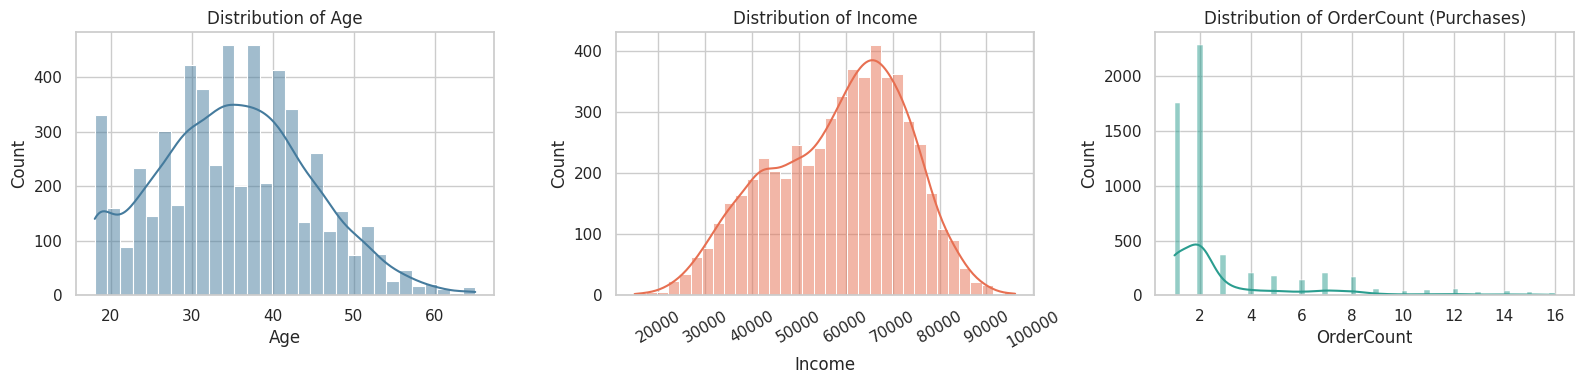

          Age   Income  OrderCount
count  5630.0   5630.0      5630.0
mean     35.2  58484.3         3.0
std       9.5  14450.7         2.9
min      18.0  15000.0         1.0
25%      28.0  47800.0         1.0
50%      35.0  60600.0         2.0
75%      42.0  69475.0         3.0
max      65.0  96100.0        16.0

Skewness:
 Age           0.20
Income       -0.33
OrderCount    2.28
dtype: float64


In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, colr in zip(axes, ["Age", "Income", "OrderCount"], ["#457b9d", "#e76f51", "#2a9d8f"]):
    sns.histplot(df[col], kde=True, ax=ax, color=colr)
    ax.set_title(f"Distribution of {col}" + (" (Purchases)" if col == "OrderCount" else ""))
    if col == "Income":
        ax.tick_params(axis="x", rotation=30)
save_fig("02_univariate_age_income_purchases.png")

print(df[["Age", "Income", "OrderCount"]].describe().round(1))
print("\nSkewness:\n", df[["Age", "Income", "OrderCount"]].skew().round(2))

**Interpretation:**
- **Age** (simulated) is roughly bell-shaped, centred near 35 years (mean 35.2, range 18-65, skewness 0.20), so no transformation is needed. The small spike at 18 appears because simulated ages below 18 were clipped to the minimum of 18.
- **Income** (simulated) has a mean of about 58.5k and a median of 60.6k. It is slightly left-skewed (-0.33) and not a single smooth hump, because it is built from three city tiers with different base incomes.
- **Purchases (OrderCount)** is strongly **right-skewed** (skewness 2.28): the median customer has only 2 orders and 75% have 3 or fewer, while a small group of heavy buyers goes up to 16 orders. The peak at 2 is partly inflated because the ~258 missing values were filled with the median (2). A log transform would help linear models.

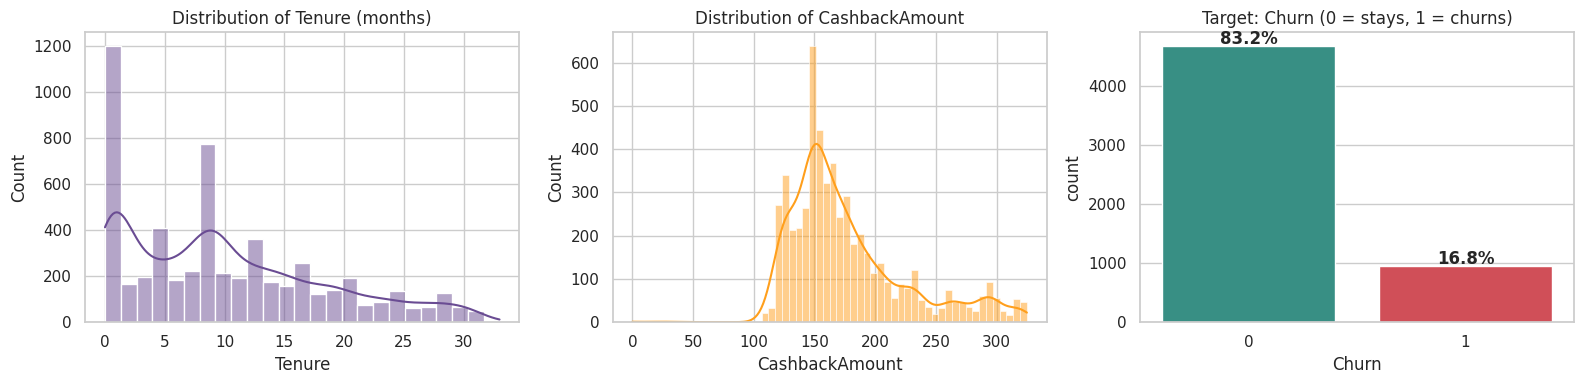

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df["Tenure"], kde=True, ax=axes[0], color="#6a4c93");           axes[0].set_title("Distribution of Tenure (months)")
sns.histplot(df["CashbackAmount"], kde=True, ax=axes[1], color="#ff9f1c");   axes[1].set_title("Distribution of CashbackAmount")

churn_pct = df["Churn"].value_counts(normalize=True).mul(100).round(1)
sns.countplot(x="Churn", data=df, ax=axes[2], palette=["#2a9d8f", "#e63946"])
for i, v in enumerate(churn_pct.sort_index()):
    axes[2].text(i, df["Churn"].value_counts().sort_index().iloc[i] + 40, f"{v}%", ha="center", fontweight="bold")
axes[2].set_title("Target: Churn (0 = stays, 1 = churns)")
save_fig("03_univariate_tenure_cashback_churn.png")

**Interpretation:**
- **Tenure** is right-skewed with a median of 9 months and a large group of very new customers (0-3 months).
- **CashbackAmount** is also right-skewed; most customers receive between about 146 and 196.
- **Target imbalance:** only about **17% of customers churn** (roughly 950 of 5,630), around 1 churner for every 5 loyal customers. A model that always predicts "stays" would get ~83% accuracy and be useless, so Recall, F1 and ROC-AUC (and possibly class weights or resampling) must be used instead of accuracy.

## Q9. Bivariate Analysis

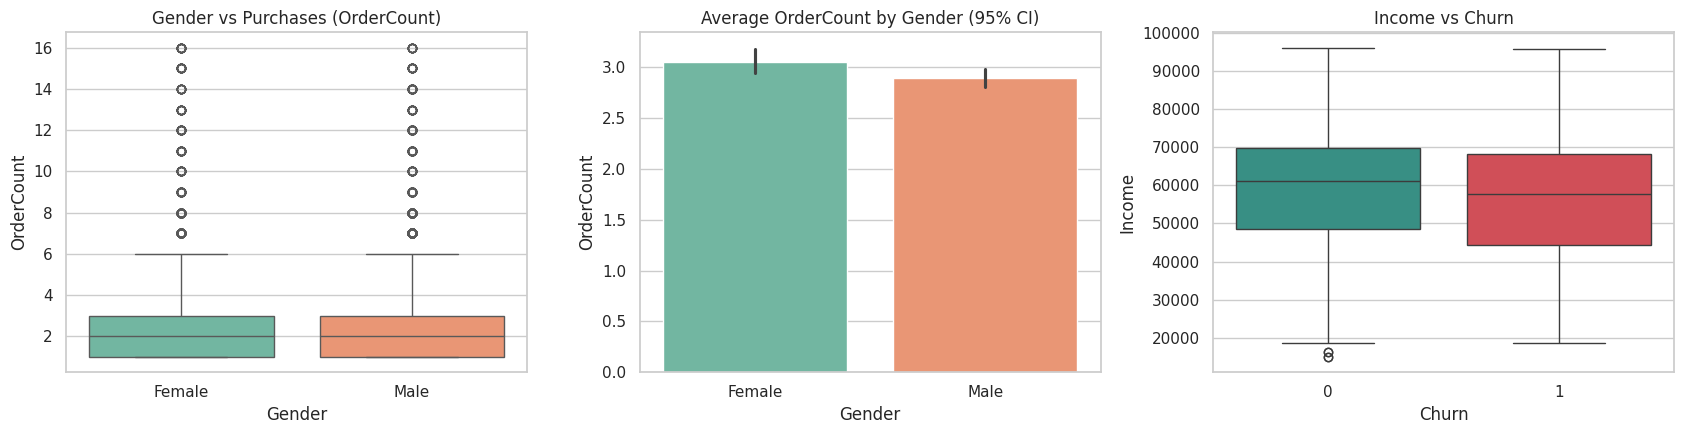

        mean  median
Gender              
Female  3.06     2.0
Male    2.90     2.0

Churn rate by Gender (%):
 Gender
Female    15.5
Male      17.7
Name: Churn, dtype: float64

Median Income by Churn:
 Churn
0    61100.0
1    57850.0
Name: Income, dtype: float64


In [24]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# Gender vs Purchases (OrderCount)
sns.boxplot(x="Gender", y="OrderCount", data=df, ax=axes[0], palette="Set2")
axes[0].set_title("Gender vs Purchases (OrderCount)")

sns.barplot(x="Gender", y="OrderCount", data=df, ax=axes[1], palette="Set2", errorbar="ci")
axes[1].set_title("Average OrderCount by Gender (95% CI)")

# Income vs Churn
sns.boxplot(x="Churn", y="Income", data=df, ax=axes[2], palette=["#2a9d8f", "#e63946"])
axes[2].set_title("Income vs Churn")
save_fig("04_bivariate_gender_income.png")

print(df.groupby("Gender")["OrderCount"].agg(["mean", "median"]).round(2))
print("\nChurn rate by Gender (%):\n", (df.groupby("Gender")["Churn"].mean() * 100).round(1))
print("\nMedian Income by Churn:\n", df.groupby("Churn")["Income"].median())

**Interpretation:**
- **Gender vs Purchases:** female customers place slightly more orders on average (3.06 vs 2.90) but the difference is only about 0.16 orders, the medians are identical (2) and the confidence intervals almost touch, so gender has **no practically meaningful effect** on purchase count. Churn rates are also close (female 15.5%, male 17.7%).
- **Income vs Churn:** the median income of churned customers (57,850) is a little lower than that of retained customers (61,100), but the boxes overlap almost completely and the correlation is only -0.06. Income is **simulated**, and the small gap comes from its link with `CityTier`, so it must not be treated as a real finding.

Real drivers of churn (using the original, non-simulated columns):

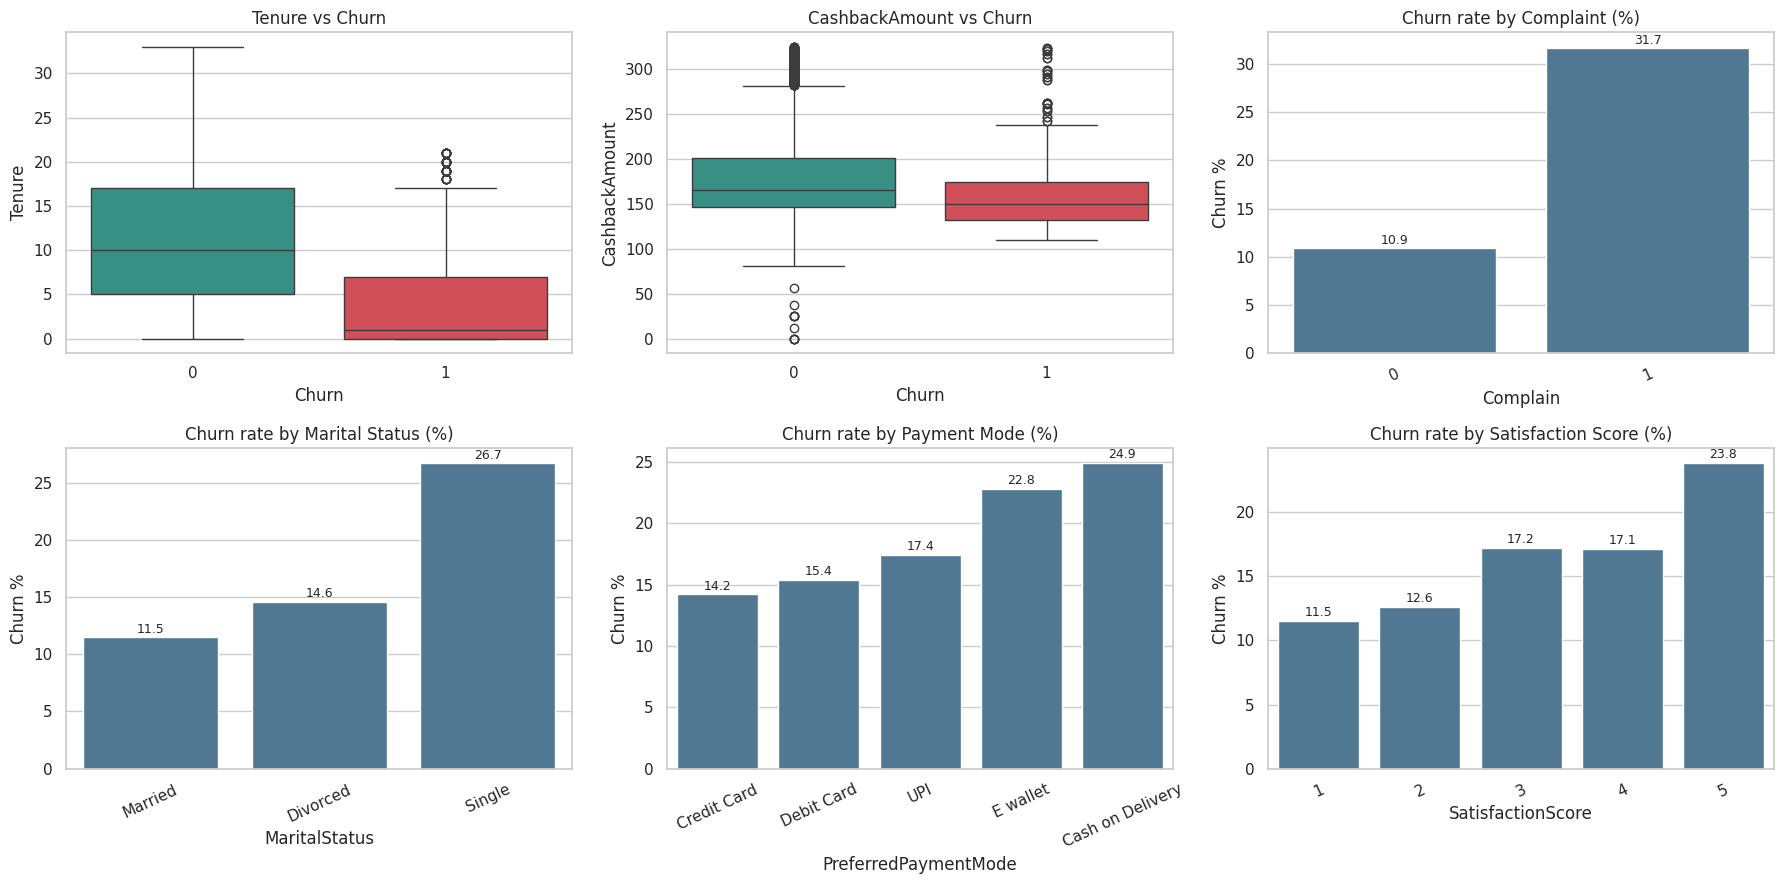

       Tenure  CashbackAmount  OrderCount  DaySinceLastOrder
Churn                                                       
0       11.39          180.63        2.99               4.71
1        3.86          160.37        2.81               3.22


In [25]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))

sns.boxplot(x="Churn", y="Tenure", data=df, ax=axes[0, 0], palette=["#2a9d8f", "#e63946"])
axes[0, 0].set_title("Tenure vs Churn")

sns.boxplot(x="Churn", y="CashbackAmount", data=df, ax=axes[0, 1], palette=["#2a9d8f", "#e63946"])
axes[0, 1].set_title("CashbackAmount vs Churn")

for ax, col, title in [(axes[0, 2], "Complain", "Churn rate by Complaint (%)"),
                       (axes[1, 0], "MaritalStatus", "Churn rate by Marital Status (%)"),
                       (axes[1, 1], "PreferredPaymentMode", "Churn rate by Payment Mode (%)"),
                       (axes[1, 2], "SatisfactionScore", "Churn rate by Satisfaction Score (%)")]:
    rate = (df.groupby(col)["Churn"].mean() * 100).round(1)
    rate = rate.sort_index() if col in ("Complain", "SatisfactionScore") else rate.sort_values()
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax, color="#457b9d")
    ax.set_title(title); ax.set_ylabel("Churn %"); ax.set_xlabel(col)
    ax.tick_params(axis="x", rotation=25)
    for i, v in enumerate(rate.values):
        ax.text(i, v + 0.4, f"{v}", ha="center", fontsize=9)
save_fig("05_bivariate_churn_drivers.png")

print(df.groupby("Churn")[["Tenure", "CashbackAmount", "OrderCount", "DaySinceLastOrder"]].mean().round(2))

**Interpretation (observed relationships, not proof of cause):**
- **Tenure** is the clearest driver: churned customers have an average tenure of only **3.9 months** versus **11.4 months** for retained customers. Most churn happens early in the customer lifetime.
- **Complaints:** customers who complained churn at **31.7%** versus **10.9%** for those who did not.
- **Marital status:** single customers churn the most (**26.7%**) compared with married (11.5%) and divorced (14.6%) customers.
- **Payment mode:** Cash on Delivery (24.9%) and E-wallet (22.8%) users churn more than credit-card users (14.2%).
- **Cashback:** churned customers received lower cashback on average (160 vs 181).
- **Counter-intuitive results:** churn rate is highest for satisfaction score 5 (23.8%) and churners placed their last order *more recently* (3.2 vs 4.7 days). These do not match business logic and may reflect how the data was recorded, so they need domain validation before being used for decisions.

## Q10. Multivariate Analysis

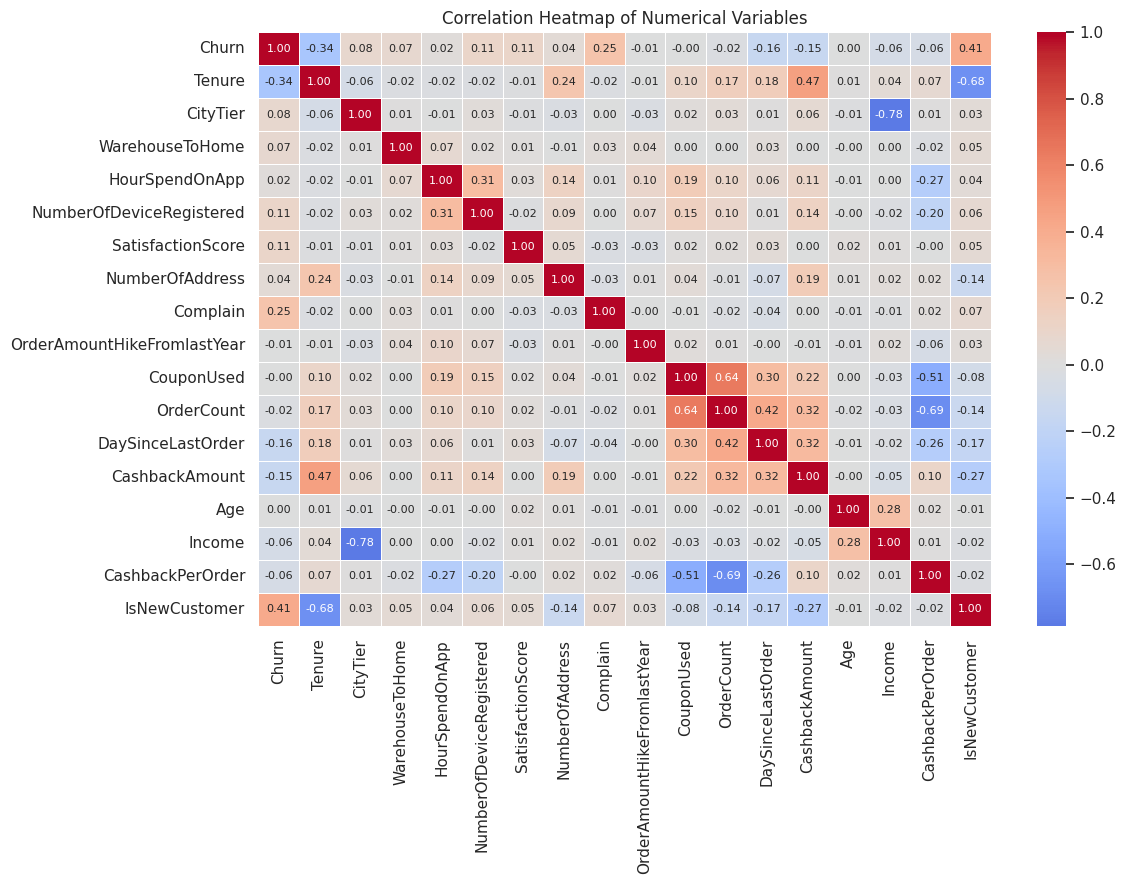

Correlation with Churn:
Tenure                        -0.340
DaySinceLastOrder             -0.156
CashbackAmount                -0.154
Income                        -0.062
CashbackPerOrder              -0.057
OrderCount                    -0.024
OrderAmountHikeFromlastYear   -0.007
CouponUsed                    -0.001
Age                            0.003
HourSpendOnApp                 0.019
NumberOfAddress                0.043
WarehouseToHome                0.074
CityTier                       0.085
SatisfactionScore              0.105
NumberOfDeviceRegistered       0.108
Complain                       0.250
IsNewCustomer                  0.414
Name: Churn, dtype: float64


In [26]:
plt.figure(figsize=(12, 9))
corr = df.select_dtypes("number").corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5, annot_kws={"size": 8})
plt.title("Correlation Heatmap of Numerical Variables")
save_fig("06_correlation_heatmap.png")

print("Correlation with Churn:")
print(corr["Churn"].drop("Churn").sort_values().round(3))

In [27]:
# Strongest correlated pairs (excluding self-correlation)
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().rename("corr").reset_index()
pairs["abs"] = pairs["corr"].abs()
pairs.sort_values("abs", ascending=False).head(6).drop(columns="abs").round(3)

,level_0,level_1,corr
45,CityTier,Income,-0.784
136,OrderCount,CashbackPerOrder,-0.689
32,Tenure,IsNewCustomer,-0.679
125,CouponUsed,OrderCount,0.641
130,CouponUsed,CashbackPerOrder,-0.509
28,Tenure,CashbackAmount,0.469


**Interpretation:**
- **Correlation with churn:** `IsNewCustomer` (+0.41, derived from Tenure), `Tenure` (-0.34) and `Complain` (+0.25) are the strongest signals, followed by `DaySinceLastOrder` (-0.16) and `CashbackAmount` (-0.15). `Age` (+0.003) and `Income` (-0.06) have essentially **no relationship** with churn, as expected for simulated columns.
- **Strong relationships between features (multicollinearity):** `CityTier` and `Income` (-0.78, because income was built from city tier), `OrderCount` and `CashbackPerOrder` (-0.69, derived from each other), `Tenure` and `IsNewCustomer` (-0.68, derived), `CouponUsed` and `OrderCount` (+0.64, frequent buyers use more coupons) and `Tenure` and `CashbackAmount` (+0.47).
- For linear models, keep only one feature from each strongly correlated pair; tree-based models handle this better.

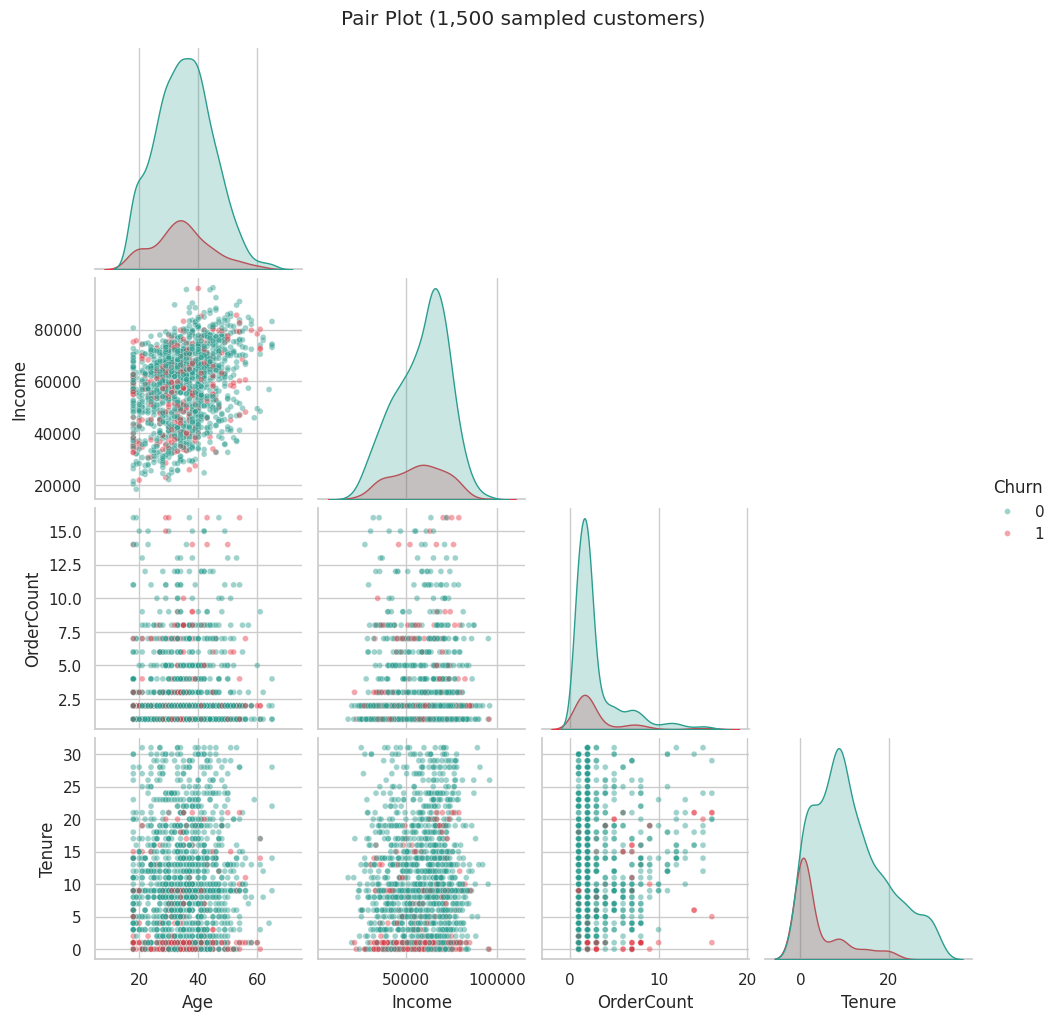

In [28]:
# Pair plot on a random sample (faster to draw, same patterns)
sample = df[["Age", "Income", "OrderCount", "Tenure", "Churn"]].sample(1500, random_state=42)
g = sns.pairplot(sample, hue="Churn", palette={0: "#2a9d8f", 1: "#e63946"},
                 corner=True, plot_kws={"alpha": 0.45, "s": 18})
g.fig.suptitle("Pair Plot (1,500 sampled customers)", y=1.02)
g.savefig(os.path.join(VIZ, "07_pairplot.png"), dpi=130, bbox_inches="tight")
plt.show()

**Interpretation:** In the scatter panels, red (churn) and green (stay) points overlap heavily for `Age` and `Income`, which confirms that these two features do not separate the classes. `Tenure` is different: churned customers are concentrated at low tenure values. `Age` and `Income` show a mild upward trend with each other (by construction of the simulated income). `OrderCount` forms horizontal/vertical bands because it holds small whole numbers. Feature interactions are therefore weak in this sample, and `Tenure` is the main feature that visibly separates churners.

---
# Part E: Data Profiling (Q11)

An automated **Pandas Profiling** (`ydata-profiling`) report summarises missing values, descriptive statistics, correlations and data quality **alerts**. We generate it **before** and **after** cleaning to show the improvement.

In [29]:
from ydata_profiling import ProfileReport

# BEFORE cleaning (merged raw data, includes CustomerID)
raw_profile = ProfileReport(df_raw, title="Raw Data Profiling Report (before cleaning)",
                            interactions=None, progress_bar=False)
raw_profile.to_file(os.path.join(REPORTS, "raw_profiling_report.html"))

# AFTER cleaning + feature engineering
clean_profile = ProfileReport(df, title="Cleaned Data Profiling Report (after cleaning)",
                              interactions=None, progress_bar=False)
clean_profile.to_file(os.path.join(REPORTS, "cleaned_profiling_report.html"))

def alert_summary(profile):
    desc = profile.get_description()
    alerts = getattr(desc, "alerts", None)
    if alerts is None and isinstance(desc, dict):
        alerts = desc.get("alerts", [])
    return alerts or []

for name, prof in [("RAW", raw_profile), ("CLEANED", clean_profile)]:
    alerts = alert_summary(prof)
    kinds = pd.Series([a.alert_type.name if hasattr(a, "alert_type") else str(a) for a in alerts]).value_counts()
    print(f"\n{name}: {len(alerts)} alerts")
    print(kinds.to_string() if len(kinds) else "no alerts")


RAW: 18 alerts
MISSING             7
HIGH_CORRELATION    6
ZEROS               3
UNIFORM             1
UNIQUE              1

CLEANED: 14 alerts
HIGH_CORRELATION    11
ZEROS                3
